In [3]:
# load jsonl dataset

import json

CONDITIONS = ['anxiety', 'depression', 'ptsd', 'autism', 'ocd', 'adhd', 'bipolar']


def load_jsonl(file_path):
    data = []
    with open(file_path, 'r') as f:
        for line in f:
            data.append(json.loads(line))
    return data
def plot_condition(condition):
    # read data
    data = load_jsonl(f'data/mindset/disclosures/{condition}_self_disclosures.jsonl')
    # plot post utc
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from datetime import datetime
    # extract post utc
    post_utc = [entry['created_utc'] for entry in data]
    # convert to datetime
    post_utc = [datetime.fromtimestamp(utc) for utc in post_utc]
    # plot histogram
    plt.figure(figsize=(10, 6))
    plt.hist(post_utc, bins=30, edgecolor='black')
    plt.title('Distribution of Post UTC')
    plt.xlabel('Post UTC')
    plt.ylabel('Frequency') 

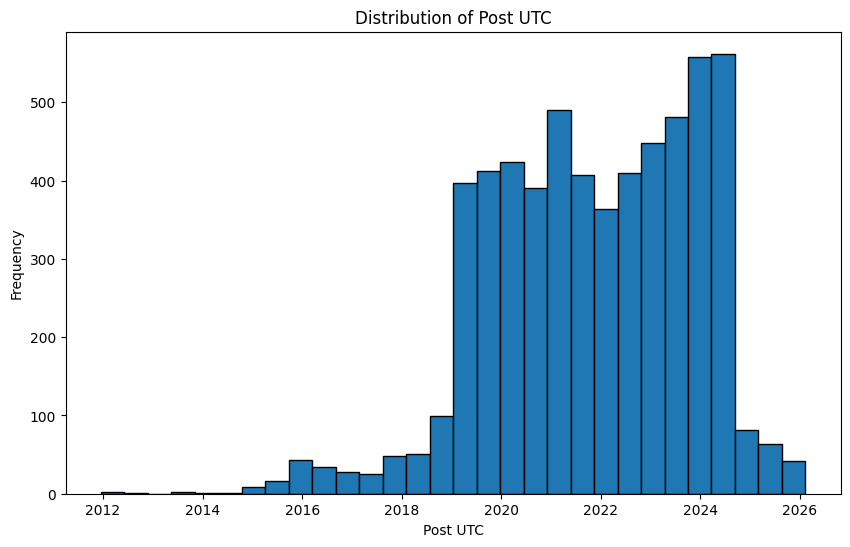

In [4]:
plot_condition('anxiety')

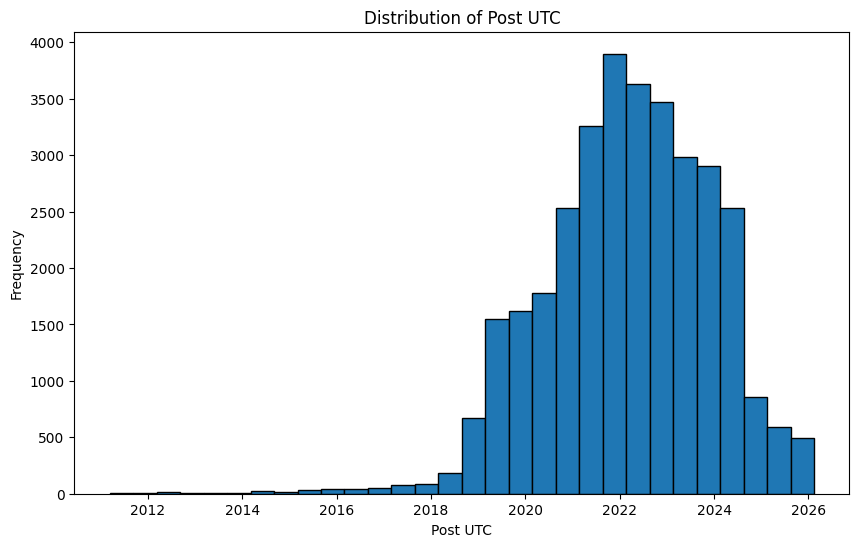

In [5]:
plot_condition('adhd')

## Per-condition posting frequency

Monthly aggregation across all conditions:
- **posts/month** — raw volume
- **unique users/month** — breadth of the active community
- **posts per user/month** — per-user posting intensity

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

def load_condition_df(condition):
    rows = load_jsonl(f'data/mindset/disclosures/{condition}_self_disclosures.jsonl')
    df = pd.DataFrame(rows)[['user_id', 'created_utc']]
    df['condition'] = condition
    df['ts'] = pd.to_datetime(df['created_utc'], unit='s')
    return df

all_df = pd.concat([load_condition_df(c) for c in CONDITIONS], ignore_index=True)

# monthly aggregation per condition
g = all_df.set_index('ts').groupby('condition')['user_id']
monthly = pd.concat([
    g.resample('MS').size().rename('posts'),
    g.resample('MS').nunique().rename('users'),
], axis=1).reset_index()
monthly['posts_per_user'] = monthly['posts'] / monthly['users']

print(monthly.groupby('condition').agg(
    months=('ts', 'count'),
    total_posts=('posts', 'sum'),
    peak_month=('posts', 'max'),
    median_posts_per_user=('posts_per_user', 'median'),
))
monthly.head()

            months  total_posts  peak_month  median_posts_per_user
condition                                                         
adhd           180        33359         710               1.113228
anxiety        171         5890         201               1.186667
autism         173        22777         551               1.222222
bipolar        185        14420         288               1.153110
depression     165         8799         160               1.134752
ocd            170         4255         140               1.204651
ptsd           146         3648          84               1.152174


,condition,ts,posts,users,posts_per_user
0,adhd,2011-03-01,1,1,1.0
1,adhd,2011-04-01,0,0,NaN
2,adhd,2011-05-01,0,0,NaN
3,adhd,2011-06-01,1,1,1.0
4,adhd,2011-07-01,0,0,NaN


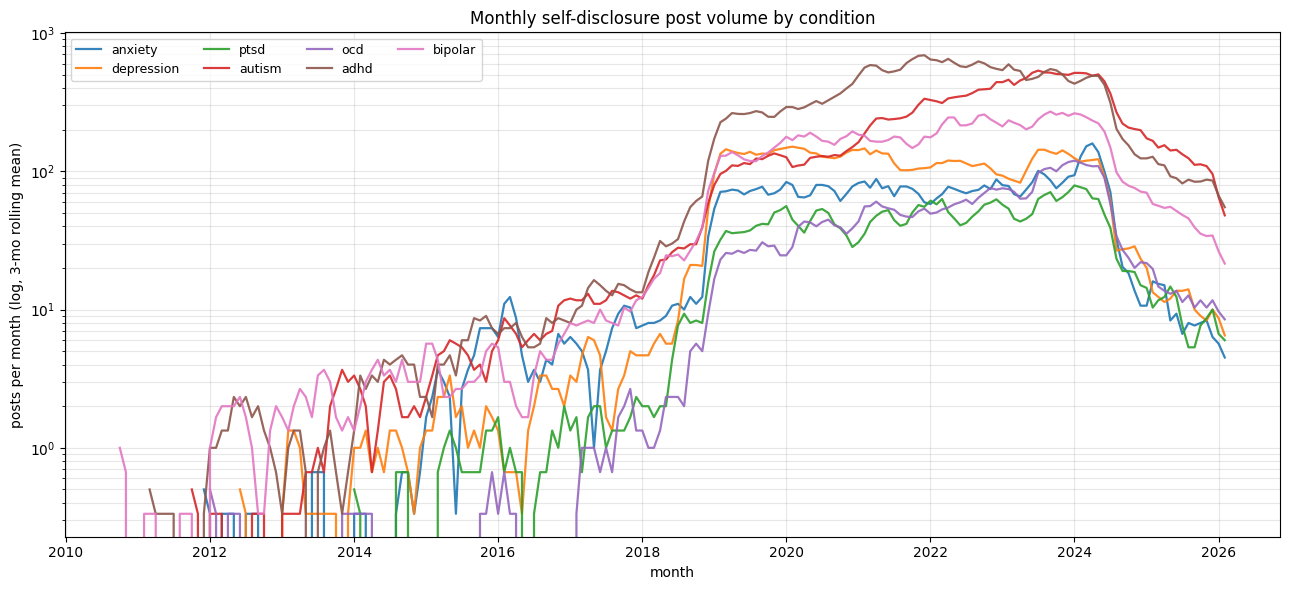

In [7]:
# Plot 1: monthly post volume, all conditions overlaid (log y so small conditions stay visible)
fig, ax = plt.subplots(figsize=(13, 6))
for c in CONDITIONS:
    sub = monthly[monthly['condition'] == c].sort_values('ts')
    smoothed = sub['posts'].rolling(3, center=True, min_periods=1).mean()
    ax.plot(sub['ts'], smoothed, label=c, alpha=0.9, linewidth=1.6)
ax.set_yscale('log')
ax.set_ylabel('posts per month (log, 3-mo rolling mean)')
ax.set_xlabel('month')
ax.set_title('Monthly self-disclosure post volume by condition')
ax.legend(ncol=4, fontsize=9, loc='upper left')
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

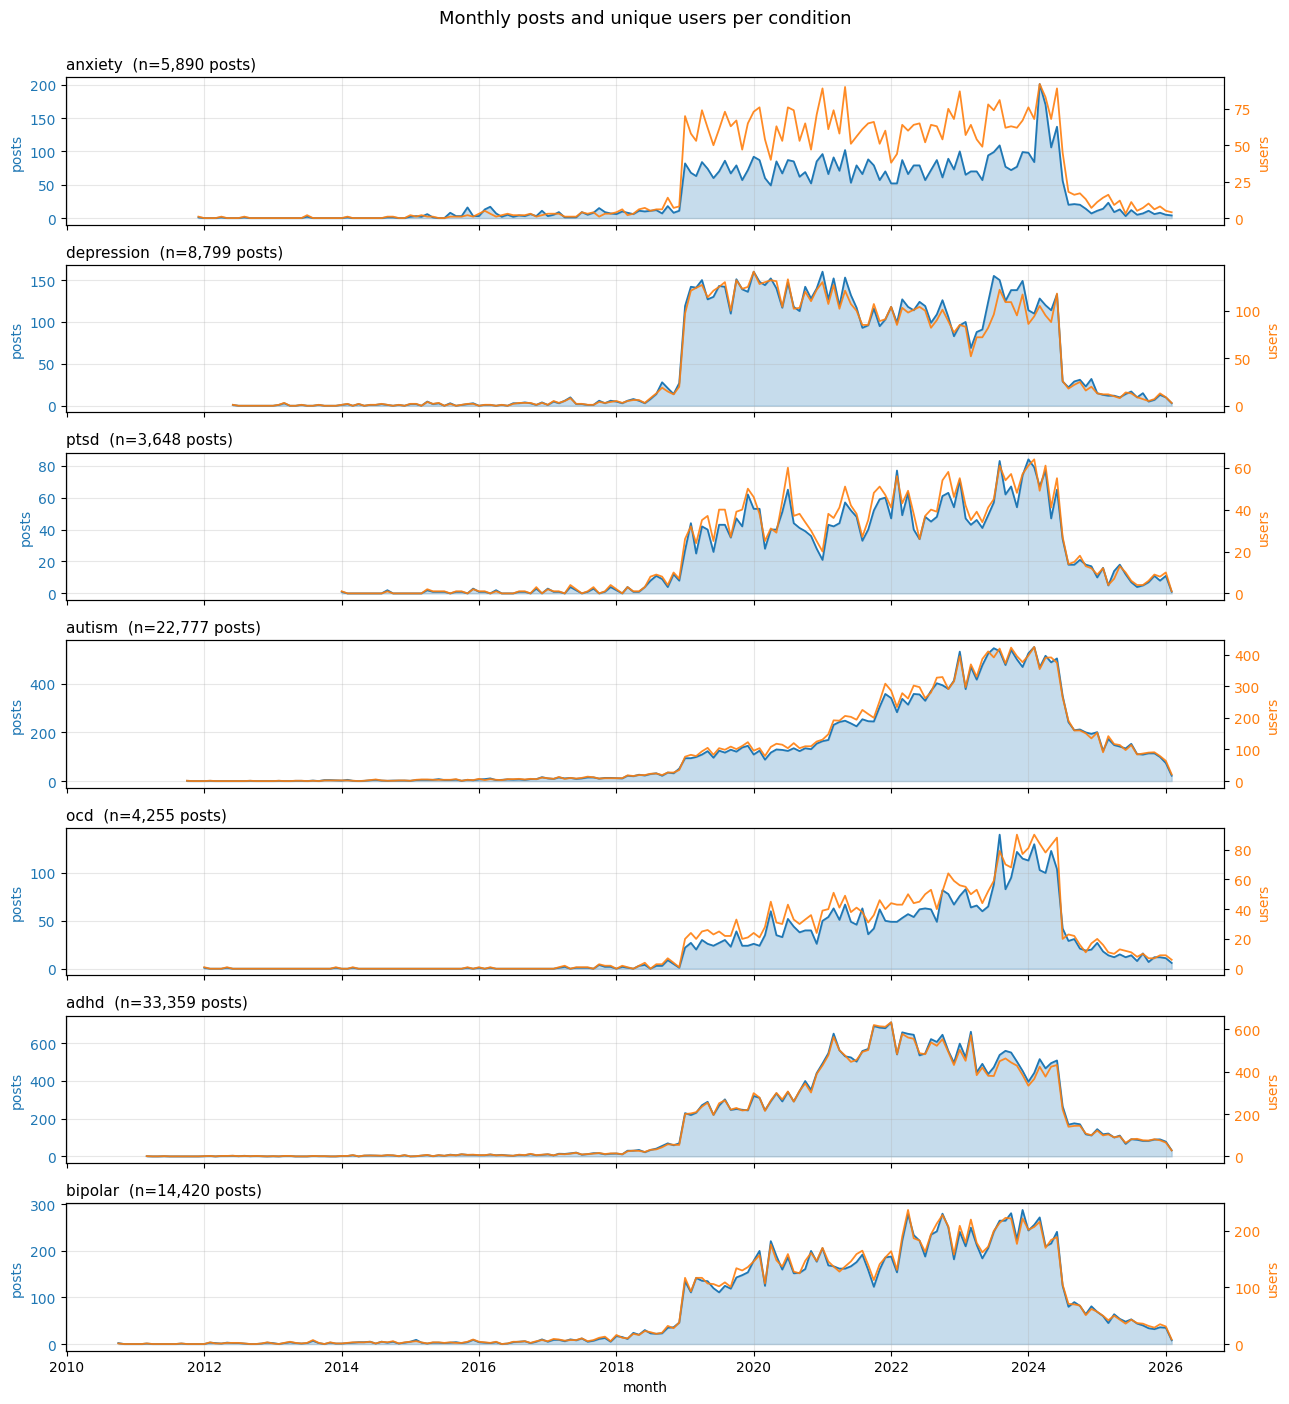

In [8]:
# Plot 2: small multiples — posts/month and unique users/month per condition (twin axes)
fig, axes = plt.subplots(len(CONDITIONS), 1,
                         figsize=(13, 2.0 * len(CONDITIONS)),
                         sharex=True)
for ax, c in zip(axes, CONDITIONS):
    sub = monthly[monthly['condition'] == c].sort_values('ts')
    ax.fill_between(sub['ts'], sub['posts'], color='tab:blue', alpha=0.25)
    ax.plot(sub['ts'], sub['posts'], color='tab:blue', linewidth=1.3, label='posts')
    ax.set_ylabel('posts', color='tab:blue')
    ax.tick_params(axis='y', labelcolor='tab:blue')

    ax2 = ax.twinx()
    ax2.plot(sub['ts'], sub['users'], color='tab:orange', linewidth=1.3, alpha=0.9, label='users')
    ax2.set_ylabel('users', color='tab:orange')
    ax2.tick_params(axis='y', labelcolor='tab:orange')

    n_total = int(sub['posts'].sum())
    ax.set_title(f'{c}  (n={n_total:,} posts)', loc='left', fontsize=11)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('month')
fig.suptitle('Monthly posts and unique users per condition', y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

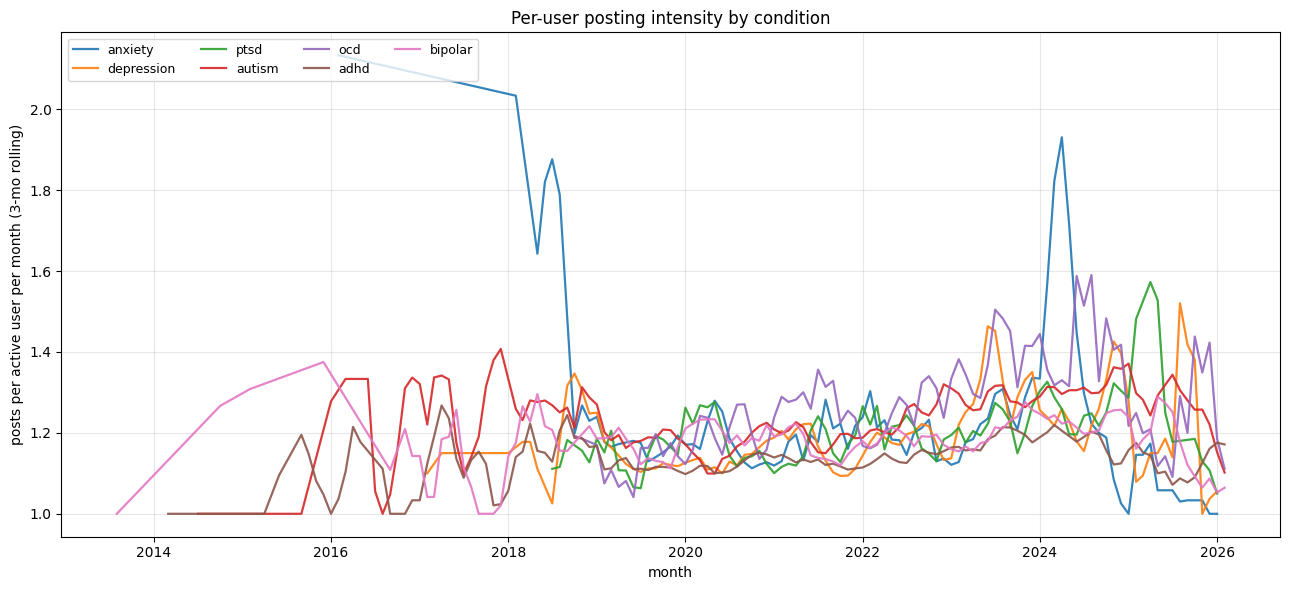

In [9]:
# Plot 3: per-user posting intensity — controls for community size
fig, ax = plt.subplots(figsize=(13, 6))
for c in CONDITIONS:
    sub = monthly[monthly['condition'] == c].sort_values('ts')
    # only show months with at least 5 active users to suppress edge spikes
    sub = sub[sub['users'] >= 5]
    smoothed = sub['posts_per_user'].rolling(3, center=True, min_periods=1).mean()
    ax.plot(sub['ts'], smoothed, label=c, alpha=0.9, linewidth=1.6)
ax.set_ylabel('posts per active user per month (3-mo rolling)')
ax.set_xlabel('month')
ax.set_title('Per-user posting intensity by condition')
ax.legend(ncol=4, fontsize=9, loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Plot 4: average disclosure posts per user, per condition
# Each user is counted once per condition. Mean answers "if you pick a random
# user from this community, how many disclosure posts did they make over all time?"
posts_per_user = (
    all_df.groupby(['condition', 'user_id']).size()
          .rename('posts').reset_index()
)
ppu_summary = posts_per_user.groupby('condition').agg(
    n_users=('user_id', 'count'),
    mean_posts=('posts', 'mean'),
    median_posts=('posts', 'median'),
    max_posts=('posts', 'max'),
).sort_values('mean_posts', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(ppu_summary.index, ppu_summary['mean_posts'],
              color='tab:blue', alpha=0.85, edgecolor='black')
for bar, (cond, row) in zip(bars, ppu_summary.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"mean={row['mean_posts']:.2f}\nn={int(row['n_users']):,} users",
            ha='center', va='bottom', fontsize=9)

ax.set_ylabel('avg disclosure posts per user (lifetime)')
ax.set_xlabel('condition')
ax.set_title('Average self-disclosure posts per user, by condition\n'
             '(median is 1 for every condition — most users post once; mean reflects the long tail of repeat posters)')
ax.grid(True, axis='y', alpha=0.3)
ax.set_ylim(0, ppu_summary['mean_posts'].max() * 1.25)
plt.tight_layout()
plt.show()

print(ppu_summary)